## t-SNE of chemical space
Compares the chemical space covered by each pharmacokinetic database (and by ChEMBL compounds that are linked to ADME assays) with a random 10% sample of rule-of-five compliant ChEMBL compounds.

Pipeline: CAS # → SMILES → Morgan fingerprints → PCA (10 components) → t-SNE (perplexity 500).

The slow steps (web lookups of SMILES, and the t-SNE itself, which takes several hours) are cached in `smiles/` and `tsne/`. Delete a cache file to recompute that step. The cached files are the exact ones used for the thesis figure.

Besides the packages of `overview.ipynb`, this notebook needs `chemplot`, `rdkit`, `scikit-learn`, `seaborn`, `requests`, `cirpy` and `tqdm` (see `requirements.txt`).

In [1]:
# For hiding pandas future warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# Imports
import os, glob
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from chemplot import Plotter
from rdkit import Chem, RDLogger
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
tqdm.pandas()

# Only show critical rdkit logs.
RDLogger.DisableLog('rdApp.*')
%matplotlib inline

# Load env variables
from dotenv import load_dotenv
load_dotenv()

/Users/m.ockhuijsen/miniforge3/envs/literature-thesis-dds/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [2]:
# Databases to plot (keys are used as file names, values as plot titles).
databases = {
    'chembl_adme_assay': 'ChEMBL ADME assays',
    'edrug': 'e-Drug3D',
    'lombardo': 'Lombardo $et$ $al.$',
    'adachi': 'Adachi $et$ $al.$',
    'comptox': 'CompTox',
    'paixao': 'Paixão $et$ $al.$',
    # Obach et al. is left out because Lombardo et al. is the updated version of this database.
}
# Databases with CAS # files in csv_files/ (created by overview.ipynb).
pk_databases = ['edrug', 'lombardo', 'adachi', 'comptox', 'paixao']

RANDOM_STATE = 3

## CAS # to SMILES
SMILES are looked up with [CAS Common Chemistry](https://commonchemistry.cas.org) (requires a free API key, set as the environment variable `CAS_API_KEY`; skipped if not set), then [PubChem](https://pubchem.ncbi.nlm.nih.gov/docs/pug-rest) and finally the [Chemical Identifier Resolver](https://cactus.nci.nih.gov/chemical/structure).

Results are cached per database in `smiles/<database>.csv`, including CAS # for which no SMILES was found (empty `smiles`). Only CAS # that are not in the cache yet are looked up; remove a row from the cache to look it up again.

In [3]:
CAS_API_KEY = os.environ.get('CAS_API_KEY')
if CAS_API_KEY:
    print('CAS api key found')

# In earlier runs, some CAS # were missing that were still easy to find.
# To add them, they were manually curated:
missing_cas = {
    # adachi
    '9007-27-6': 'CC(NC1C(OC2C(O)C(O)C=C(C(O)=O)O2)C(O)C(CO)OC1O)=O',
    '72559-06-9': 'O=C(C(NC1=O)=C2C3=NC4(CCN(CC(C)C)CC4)N2)C5=C3C(C([C@@]6(C)O/C=C/[C@H](OC)[C@H]([C@@H](OC(C)=O)[C@H](C)[C@H](O)[C@H](C)[C@@H](O)[C@@H](C)/C=C/C=C1/C)C)=O)=C(O6)C(C)=C5O',
    # comptox
    '9004-67-5': 'CO[C@@H]([C@@H](OC)[C@H]1OC)O[C@H](COC)[C@H]1O[C@@H]2O[C@H](COC)[C@@H](OC)[C@H](OC)[C@H]2OC',
    # edrug -> not able to find any missing cas #
    # 72559-06-9 -> already under adachi
    '8025-81-8': 'O=C(O[C@H](C)C/C=C/C=C/1)C[C@@H](O)[C@H](OC)[C@H]([C@@H](CC=O)C[C@@H](C)[C@H]1OC2O[C@@H]([C@@H](N(C)C)CC2)C)O[C@H]3[C@H](O)[C@H]([C@H](O[C@H](O[C@@H](C)[C@@H]4O)C[C@@]4(C)O)[C@@H](C)O3)N(C)C',
}

def cas_to_smiles(cas):
    """Resolve a CAS # to a SMILES string (pd.NA if it cannot be found)."""
    # Try to use CAS common chemistry API
    if CAS_API_KEY:
        response = requests.get("https://commonchemistry.cas.org/direct-api/detail",
                                params={"cas_rn": cas}, headers={
                "accept": "application/json",
                "x-origin": "https://commonchemistry.cas.org/api-overview",
                "X-API-KEY": CAS_API_KEY,
        },timeout=30,)
        if response.ok and response.json().get('canonicalSmile'):
            return response.json()['canonicalSmile'], 'CAS-CC'
    # Backup API: PubChem
    response = requests.get(f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{cas}/property/ConnectivitySMILES/JSON')
    if response.ok:
        return response.json()['PropertyTable']['Properties'][0]['ConnectivitySMILES'], 'PubChem'
    if cas in missing_cas.keys():
        return missing_cas[cas], 'ChemACX'
    return pd.NA, pd.NA

CAS api key found


In [4]:
# Helper functions
cas_pattern = r"\d{2,7}-\d{2}-\d"
def load_cas_file(path):
    """Load and check the CAS numbers in the csv file."""
    series = pd.read_csv(path, dtype="string").iloc[:, 0].str.replace(r"\s+", "", regex=True)
    is_cas = series.str.fullmatch(cas_pattern)
    invalid = series[~is_cas].unique()
    if len(invalid):
        print(f"{path}: not matching CAS format: {list(invalid)}")
    return pd.Index(series[is_cas].unique())

def get_database_smiles(db_name):
    """Return a dataframe with the CAS #, SMILES and source of a database, looking up only CAS # that are not cached yet."""
    cas_numbers = load_cas_file(f'csv_files/{db_name}.csv')
    cache_file = Path(f'smiles/{db_name}.csv')
    columns = ['CAS', 'smiles', 'source']

    # Only run API calls if the csv is not there yet.
    if cache_file.exists():
        cache = pd.read_csv(cache_file, dtype='string')
    else:
        cache = pd.DataFrame(columns=columns, dtype='string')

    # Re-run cas numbers
    new_cas = cas_numbers.difference(cache.CAS)
    if len(new_cas):
        results = [cas_to_smiles(cas) for cas in tqdm(new_cas, desc=db_name)]
        smiles, sources = zip(*results)
        new = pd.DataFrame({'CAS': new_cas, 'smiles': smiles, 'source': sources}, dtype='string')
        cache = pd.concat([cache, new], ignore_index=True)

    df = cache[cache.CAS.isin(cas_numbers)]
    if len(new_cas) or len(df) != len(cache):
        df.to_csv(cache_file, index=False)
    print(f'{db_name}: {len(df)} CAS #, {df.smiles.isna().sum()} without SMILES')
    print(df.source.value_counts(dropna=False).to_string())
    return df.dropna(subset=['smiles'])

In [5]:
pk_smiles = {}
for db_name in pk_databases:
    if 'lombardo' in db_name.lower():
        continue
    pk_smiles[db_name] = get_database_smiles(db_name)
# pk_smiles = {db_name: get_database_smiles(db_name) for db_name in pk_databases}
# From dict above, the following numbers of CAS # are missing:
# adachi: 365 CAS #, 0 without SMILES
# paixao: 164 CAS #, 0 without SMILES
# comptox: 180 CAS #, 1 without SMILES
# lombardo: 1352 CAS #, 0 without SMILES
# edrug: 1831 CAS #, 32 without SMILES

edrug: 1831 CAS #, 32 without SMILES
source
CAS-CC     1637
PubChem     161
<NA>         32
ChemACX       1
adachi: 365 CAS #, 0 without SMILES
source
CAS-CC     347
PubChem     16
ChemACX      2
comptox: 180 CAS #, 1 without SMILES
source
CAS-CC     175
PubChem      3
<NA>         1
ChemACX      1
paixao: 164 CAS #, 0 without SMILES
source
CAS-CC    164


## ChEMBL reference sets
Two sets of compounds were downloaded from the [ChEMBL](https://www.ebi.ac.uk/chembl/) web interface (22 September 2025):

1. **Rule of five compliant compounds** (`datasets/ChEMBL-Ro5/chembl_ro5_compounds.csv.zip`, 1,651,613 compounds): all compounds with `#RO5 Violations (Lipinski) = 0`. A random 10% sample is used as the background of the plots. The file is too large for GitHub and is therefore not included in the repository; download it from ChEMBL (Compounds → filter `#RO5 Violations (Lipinski)` to 0 → Download CSV) if you want to rerun this step.
2. **Compounds linked to human ADME assays** (`datasets/ChEMBL-ADME-assays/*.csv`): there is no direct way to go from assay IDs to compound IDs in the ChEMBL API, so the assay IDs were retrieved with the API (cell below) and pasted into the compound search of the ChEMBL website in chunks of 1024 IDs (the maximum), after which every result was downloaded as csv.

In [6]:
def write_chembl_assay_queries(path='datasets/ChEMBL-ADME-assays/queries.txt', chunk_size=1024):
    """Fetch the IDs of all human ADME assays from ChEMBL and write the compound search queries for the ChEMBL website."""
    from chembl_webresource_client.new_client import new_client
    assays = new_client.assay.filter(assay_type__exact='A', assay_classifications_level2__exact='mammalia',
                                     assay_organism__exact='Homo sapiens').only('assay_chembl_id')
    assay_ids = [assay['assay_chembl_id'] for assay in tqdm(assays, desc='ChEMBL assays')]
    with open(path, 'w') as f:
        for i in range(0, len(assay_ids), chunk_size):
            f.write(f"_metadata.related_assays.all_chembl_ids:({' OR '.join(assay_ids[i:i + chunk_size])})\n")
    print(f'{len(assay_ids)} assay IDs written as {-(-len(assay_ids) // chunk_size)} queries to {path}')

# Only needed when the downloaded csv files are not available.
if not glob.glob('datasets/ChEMBL-ADME-assays/*.csv'):
    write_chembl_assay_queries()

In [7]:
def load_chembl_ro5_sample(frac=0.1):
    """Random sample of the ChEMBL compounds with zero rule of five violations."""
    df = pd.read_csv('datasets/ChEMBL-Ro5/chembl_ro5_compounds.csv.zip', sep=';', usecols=['Smiles'])
    return df.rename(columns={'Smiles': 'smiles'}).sample(frac=frac, random_state=RANDOM_STATE)

def load_chembl_adme_assay_compounds():
    """Unique ChEMBL compounds linked to human ADME assays."""
    files = sorted(glob.glob('datasets/ChEMBL-ADME-assays/*.csv'))
    df = pd.concat([pd.read_csv(file, sep=';', usecols=['ChEMBL ID', 'Smiles']) for file in files], ignore_index=True)
    return df.drop_duplicates(subset='ChEMBL ID').rename(columns={'Smiles': 'smiles'})

## t-SNE input
All SMILES are combined into one dataframe and canonicalized with RDKit, which also removes SMILES that RDKit cannot parse.

In [8]:
def canonical_smiles(smiles):
    """Canonical SMILES according to RDKit, or pd.NA if the SMILES cannot be parsed."""
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol) if mol is not None and mol.GetNumAtoms() else pd.NA

tsne_input_file = Path('tsne/tsne_input.csv.gz')
if tsne_input_file.exists():
    tsne_input = pd.read_csv(tsne_input_file)
else:
    smiles_sets = {'chembl_ro5': load_chembl_ro5_sample(), 'chembl_adme_assay': load_chembl_adme_assay_compounds(), **pk_smiles}
    tsne_input = pd.concat([df[['smiles']].assign(database=db_name) for db_name, df in smiles_sets.items()], ignore_index=True)
    tsne_input['smiles'] = tsne_input.smiles.dropna().progress_apply(canonical_smiles)
    tsne_input = tsne_input.dropna().astype('string')
    tsne_input.to_csv(tsne_input_file, index=False)

tsne_input.database.value_counts()

database
chembl_adme_assay    183572
chembl_ro5           165159
edrug                  1799
lombardo               1348
adachi                  365
comptox                 179
paixao                  164
Name: count, dtype: int64

## t-SNE
Morgan fingerprints (radius 2, 2048 bits) are reduced to 10 principal components, which are embedded in two dimensions with t-SNE (perplexity 500) using the "structural" similarity mode of [ChemPlot](https://github.com/mcsorkun/ChemPlot). The t-SNE takes several hours; its result is cached in `tsne/tsne_coordinates.csv.gz`.

In [9]:
tsne_file = Path('tsne/tsne_coordinates.csv.gz')
if tsne_file.exists():
    tsne_df = pd.read_csv(tsne_file)
else:
    data = tsne_input
    chemplot_plotter_tsne = Plotter.from_smiles(data['smiles'], target=data['database'], target_type='C', sim_type="structural")
    tsne = chemplot_plotter_tsne.tsne(perplexity=500, pca=True, random_state=RANDOM_STATE)
    tsne_df = pd.DataFrame(tsne).rename(columns={'target': 'database'})
    tsne_df.to_csv(tsne_file, index=False, float_format='%.6f')

tsne_df.head(10)

,t-SNE-1,t-SNE-2,database
0,-88.855812,-3.798267,chembl_ro5
1,22.860159,73.820007,chembl_ro5
2,48.285233,90.900032,chembl_ro5
3,-77.298477,56.198895,chembl_ro5
4,41.195213,54.384075,chembl_ro5
5,7.805960,23.282339,chembl_ro5
6,16.453335,56.663162,chembl_ro5
7,-22.626457,-78.303383,chembl_ro5
8,31.055412,-20.307508,chembl_ro5
9,-30.241976,-54.898968,chembl_ro5


## Plotting

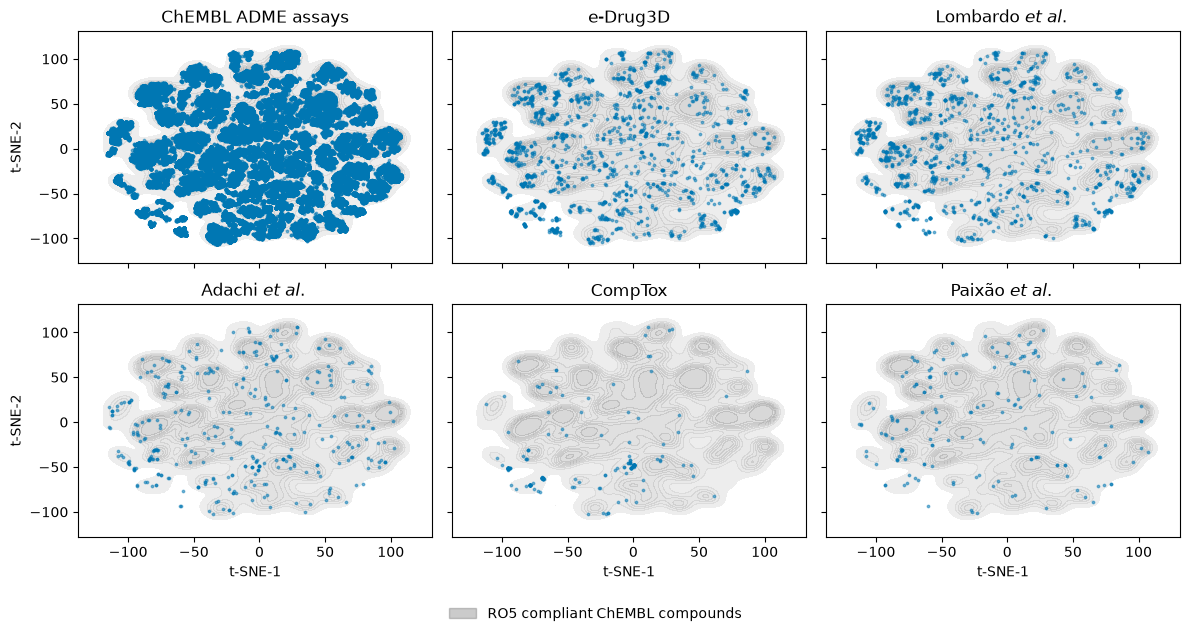

In [10]:
kde_color, point_color = '#333333', '#0077b3'

fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(12, 6))
chembl_df = tsne_df[tsne_df.database == 'chembl_ro5']

for ax, (db_name, db_label) in zip(axs.flat, databases.items()):
    # Plot kernel density estimation of the ChEMBL rule of five compliant compounds
    sns.kdeplot(x=chembl_df['t-SNE-1'], y=chembl_df['t-SNE-2'], ax=ax, fill=True, alpha=0.25, color=kde_color)
    # Plot scatterplot of the database
    db_df = tsne_df[tsne_df.database == db_name]
    ax.scatter(db_df['t-SNE-1'], db_df['t-SNE-2'], s=3, alpha=0.5, c=point_color)
    ax.set_title(db_label)

fig.tight_layout()
chembl_patch = mpatches.Patch(color=kde_color, alpha=0.25, label='RO5 compliant ChEMBL compounds')
fig.legend(handles=[chembl_patch], loc='upper center', bbox_to_anchor=(0.5, 0), frameon=False)

plt.savefig('plots/tSNE_chemical_space.png', dpi=400, bbox_inches='tight')
plt.savefig('plots/tSNE_chemical_space.pdf', bbox_inches='tight')